# Portfolio Optimisation Using Frank Wolfe Variants


## Brief description of what we want to do

- We have n available assets.
- We call xi the quantity of money invested on the i-th asset during the
considered period and with ri the returns on the i-th asset.
- We have two different constraints:
    - Non-negativity for the variables (i.e., xi ≥ 0). Meaning that short selling (selling asset that we still don’t own) is not allowed.
    - Budget constraint: $\sum_{i = 1}^{n} = B$, the total amount of money invested needs to be equal to the budget B (B can be simply set to 1).

- $r \in \mathbb{R}^n $ is a randomly generated vector with mean $\hat{r}$ and covariance $\sum$

- Expected return will be $\hat{r}^Tx$ and variance $x^T\sum x$
- Classic portfolio problem, described by Markowits (1952), is a convex quadratic
programming problem:
$$
\begin{aligned}
\min_{x \in \mathbb{R}^n} \quad & \gamma x^\top \Sigma x - \bar{r}^\top x \\
\text{s.t.} \quad & e^\top x = 1 \\
& x \ge 0
\end{aligned}
$$
- with $\gamma > 0$ risk-aversion parameter.
- GOAL: Finding the set of assets that minimises the variance (risk connected to the given portfolio) while maximising the expected return (we obviously need to satisfy budget and non-negativity constraints).

## Import Libraries and Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import Oracle 
importlib.reload(Oracle)
from Oracle import PortfolioOptimisation_rolling, PortfolioOptimisation_Whole_Dataset
import time
from scipy.stats import skew, kurtosis

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P 500': 'SP500.xlsx'
}
datasets = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    datasets[name] = data
    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    print(f"Number of Missing values: {data.isna().sum().sum()}")




Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Number of Missing values: 0

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Number of Missing values: 0

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Number of Missing values: 0


## Initial EDA

### Asset Return Statistics

In [2]:
asset_return_stats = []

for name, data in datasets.items():

    average_returns = data.mean(axis=0, skipna=True)


    asset_return_stats.append({
        'Dataset': name,
        'Number of Assets': len(average_returns),
        'Mean Average Return': average_returns.mean(),
        'Median Average Return': average_returns.median(),
        'Std Average Return': average_returns.std(ddof=1),
        'Minimum Average Return': average_returns.min(),
        'Maximum Average Return': average_returns.max(),
        'Skewness': skew(average_returns),
        'Kurtosis': kurtosis(average_returns)
    })


asset_return_stats_df = pd.DataFrame(asset_return_stats)

print(asset_return_stats_df.to_string(index=False))

 Dataset  Number of Assets  Mean Average Return  Median Average Return  Std Average Return  Minimum Average Return  Maximum Average Return  Skewness  Kurtosis
DowJones                28             0.002885               0.002506            0.001258                0.001278                0.006054  1.288624  0.671913
 FTSE100                83             0.002508               0.002507            0.001506               -0.000610                0.008018  0.807218  1.337827
 S&P 500               442             0.002546               0.002339            0.001471               -0.000626                0.010325  1.499171  4.517561


### Dataset Summary

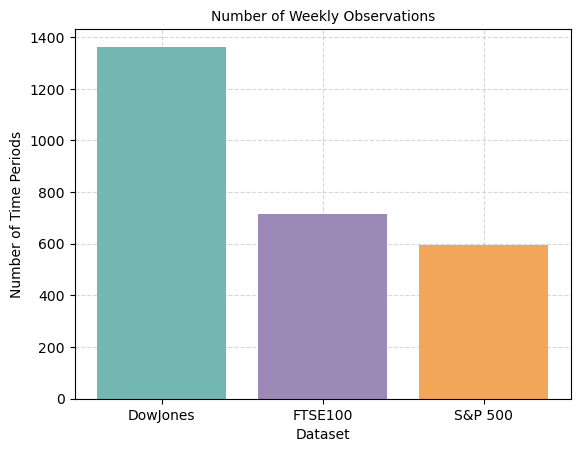

In [3]:

summary = []
for name, data in datasets.items():
    values = data.to_numpy().flatten()
    summary.append({
        "Dataset": name,
        "Number of Assets": data.shape[1],
        "Number of Time Periods": data.shape[0],
        "Total Observations": data.size,
        "Mean Return": np.mean(values),
        "Median Return": np.median(values),
        "Std Return": np.std(values, ddof=1),
        "Minimum Return": np.min(values),
        "Maximum Return": np.max(values),
        "Skewness": skew(values),
        "Kurtosis": kurtosis(values)
    })


summary_df = pd.DataFrame(summary)

x = summary_df["Dataset"]
y = summary_df["Number of Time Periods"]



plt.title(
    "Number of Weekly Observations",
    fontsize = 10
)

plt.xlabel("Dataset")
plt.ylabel("Number of Time Periods")
bars = plt.bar(x, y, color=["#72B7B2", "#9C89B8", "#F2A65A"],zorder=2)

plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)



### Correlation

In [4]:

correlation_results = []

for name, data in datasets.items():
    corr = data.corr()  
    upper_values = corr.values[np.triu_indices_from(corr.values, k=1)]
    upper_values = upper_values[np.isfinite(upper_values)]    
    correlation_results.append({
        "Dataset": name,
        "Mean Correlation": np.mean(upper_values),
        "Median Correlation": np.median(upper_values),
        "Minimum Correlation": np.min(upper_values),
        "Maximum Correlation": np.max(upper_values)
    })

correlation_df = pd.DataFrame(correlation_results)

print(correlation_df.to_string(index=False))



 Dataset  Mean Correlation  Median Correlation  Minimum Correlation  Maximum Correlation
DowJones          0.336582            0.325762             0.100503             0.787045
 FTSE100          0.345084            0.338179            -0.089827             0.845918
 S&P 500          0.412351            0.406816            -0.008174             0.984175


## Initial Results Per Algorithm

In [5]:
dataset_paths = {
    'DowJones': 'DowJones.xlsx', 
    'FTSE100': 'FTSE100.xlsx',
    'S&P500': 'SP500.xlsx'
}

all_results = {}
summary_list = []

for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma =1)

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    all_results[name] = results

    for variant, result in results.items():
        history = result['history']
        summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history),
            'Final Objective': history['Objective'].iloc[-1],
            'Final Duality Gap': history['Duality Gap'].iloc[-1],
            'Active Size (final)': history['Active Set Size'].iloc[-1],
            'Time (s)': result['time']
        })

    
summary_df = pd.DataFrame(summary_list)
print("\n" + summary_df.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones        FW              28              1363          29        -0.004183       9.447384e-07                    4  0.003427
DowJones      ASFW              28              1363           9        -0.004183       6.307742e-08                    4  0.000997
DowJones      PWFW              28              1363          13        -0.004183       3.594216e-07                    4  0.001993
 FTSE100        FW              83               717        4172        -0.005239       9.939590e-07                    5  0.505020
 FTSE100      ASFW              83               717          11        -0.005240       3.355678e-07                    4  0.001513
 FTSE10

## Active set analysis

In [28]:
for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1)
    results = model.run_all_fw(max_iter=1000, tol=1e-6)
    asset_names = list(data.columns)
    print(f"Dataset: {name}")
    for variant, result in results.items():
        x_final = result['x']
        active = np.where(np.abs(x_final) > 1e-6)[0]
        print(f"\n{variant}")
        print(f"Number of active assets: {len(active)}")
        for i in active:
            print(f"  {asset_names[i]}: {x_final[i]:.6f}")

Dataset: DowJones

FW
Number of active assets: 4
  0: 0.176047
  17: 0.310122
  18: 0.452448
  21: 0.061383

ASFW
Number of active assets: 4
  0: 0.175701
  17: 0.310349
  18: 0.452367
  21: 0.061583

PWFW
Number of active assets: 4
  0: 0.175725
  17: 0.310312
  18: 0.452495
  21: 0.061469
Dataset: FTSE100

FW
Number of active assets: 5
  0: 0.000569
  63: 0.069158
  65: 0.350784
  77: 0.296893
  82: 0.282596

ASFW
Number of active assets: 4
  63: 0.068878
  65: 0.350648
  77: 0.297209
  82: 0.283265

PWFW
Number of active assets: 4
  63: 0.068679
  65: 0.350837
  77: 0.297191
  82: 0.283293
Dataset: S&P500

FW
Number of active assets: 6
  0: 0.005959
  61: 0.181093
  86: 0.224359
  95: 0.149236
  147: 0.311750
  171: 0.127602

ASFW
Number of active assets: 5
  61: 0.183045
  86: 0.224846
  95: 0.149846
  147: 0.313047
  171: 0.129216

PWFW
Number of active assets: 5
  61: 0.183152
  86: 0.224723
  95: 0.149841
  147: 0.313087
  171: 0.129197


## Some Graphics 

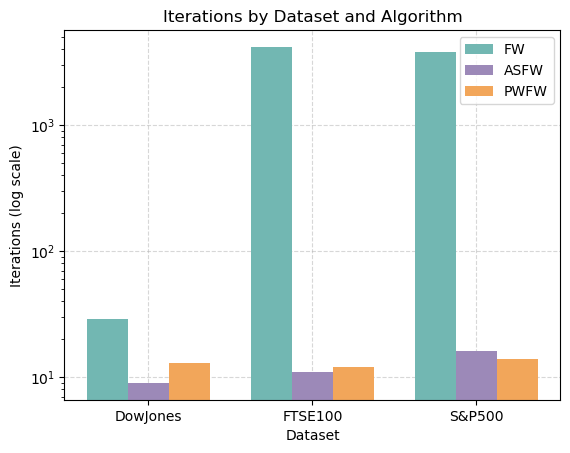

In [6]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["FW", "ASFW", "PWFW"]
datasets = summary_df["Dataset"].unique()

x = np.arange(len(datasets))
width = 0.25

colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

for i, m in enumerate(methods):
    subset = summary_df[summary_df["Algorithm"] == m].set_index("Dataset")
    values = subset.reindex(datasets)["Iterations"]

    plt.bar(x + (i - 1) * width, values, width, label=m, color=colours[i], zorder=2)

plt.yscale("log")

plt.xlabel("Dataset")
plt.ylabel("Iterations (log scale)")
plt.title("Iterations by Dataset and Algorithm")
plt.xticks(x, datasets)

plt.legend()
plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)



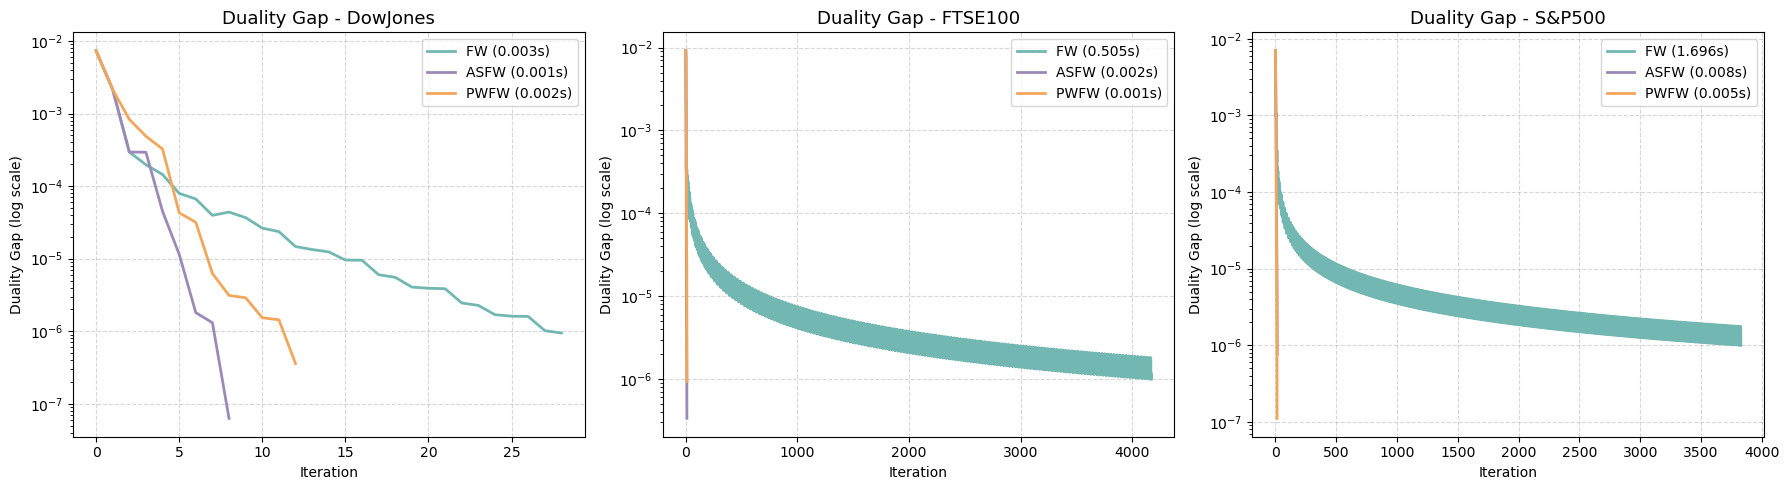

In [7]:
colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, results) in enumerate(all_results.items()):

    ax = axes[idx]

    for i, (variant, result) in enumerate(results.items()):

        history = result["history"]

        ax.semilogy(
            history["Iteration"],
            history["Duality Gap"],
            label=f"{variant} ({result['time']:.3f}s)",
            linewidth=2,
            color=colours[i],
            zorder=2
        )

    ax.set_title(f"Duality Gap - {name}", fontsize=13)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Duality Gap (log scale)")
    ax.legend()
    ax.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)

plt.tight_layout()
plt.show()

## Diminishing Gradient Method vs Exact Line Search

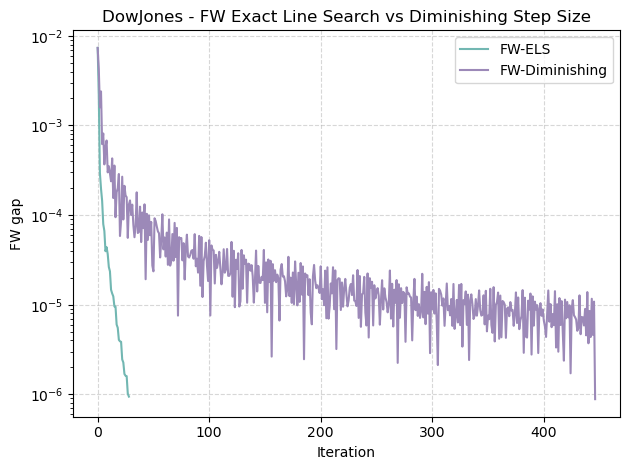

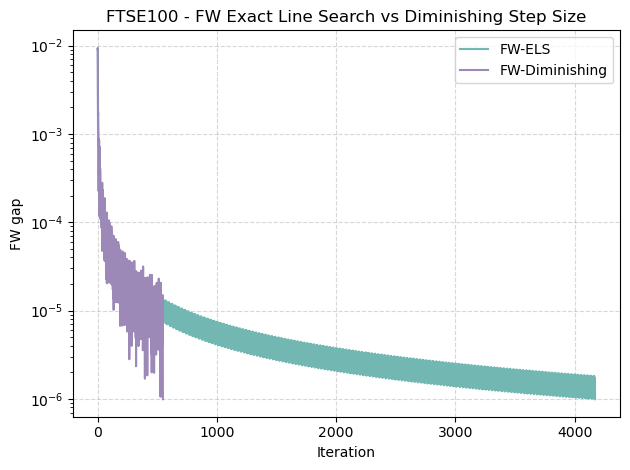

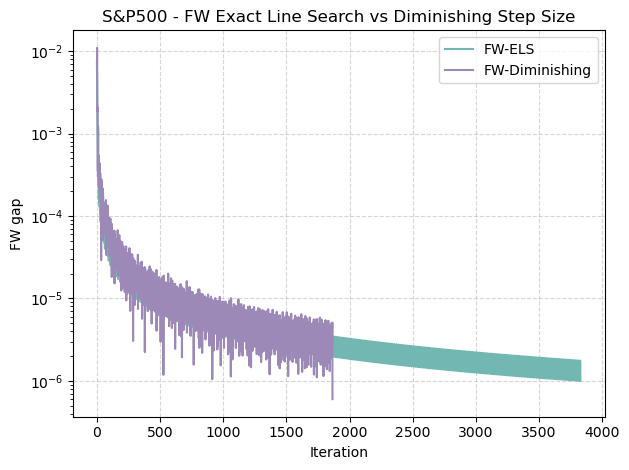


 Dataset         Method  Active assets     Time  Iterations  Final objective    Final gap
DowJones         FW-ELS              4 0.003007          29        -0.004183 9.447384e-07
DowJones FW-Diminishing              4 0.013991         447        -0.004183 8.847010e-07
 FTSE100         FW-ELS              5 0.390099        4172        -0.005239 9.939590e-07
 FTSE100 FW-Diminishing              4 0.022044         548        -0.005240 9.939650e-07
  S&P500         FW-ELS              6 0.362439        3829        -0.007494 9.986227e-07
  S&P500 FW-Diminishing              5 0.076639        1866        -0.007494 6.005146e-07


In [8]:
fw_comparison = []

colours = ["#72B7B2", "#9C89B8"]

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name="Assets_Returns", header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1)

    x_fw_exact, hist_fw_exact, time_fw_exact = model.fw(
        max_iter=10000,
        use_exact_line_search=True
    )

    x_fw_dim, hist_fw_dim, time_fw_dim = model.fw(
        max_iter=10000,
        use_exact_line_search=False
    )

    plt.semilogy(
        hist_fw_exact["Iteration"],
        hist_fw_exact["Duality Gap"],
        label="FW-ELS",
        color=colours[0],
        zorder=2
    )

    plt.semilogy(
        hist_fw_dim["Iteration"],
        hist_fw_dim["Duality Gap"],
        label="FW-Diminishing",
        color=colours[1],
        zorder=2
    )

    plt.xlabel("Iteration")
    plt.ylabel("FW gap")
    plt.title(f"{name} - FW Exact Line Search vs Diminishing Step Size")
    plt.legend()
    plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)

    plt.tight_layout()
    plt.show()

    fw_comparison.append({
        "Dataset": name,
        "Method": "FW-ELS",
        "Active assets": np.sum(x_fw_exact > 1e-6),
        "Time": time_fw_exact,
        "Iterations": len(hist_fw_exact),
        "Final objective": hist_fw_exact["Objective"].iloc[-1],
        "Final gap": hist_fw_exact["Duality Gap"].iloc[-1]
    })

    fw_comparison.append({
        "Dataset": name,
        "Method": "FW-Diminishing",
        "Active assets": np.sum(x_fw_dim > 1e-6),
        "Time": time_fw_dim,
        "Iterations": len(hist_fw_dim),
        "Final objective": hist_fw_dim["Objective"].iloc[-1],
        "Final gap": hist_fw_dim["Duality Gap"].iloc[-1]
    })

fw_comparison_df = pd.DataFrame(fw_comparison)

print("\n" + fw_comparison_df.to_string(index=False))

## FW-LMO vs PGD-PROJECTION

In [9]:
import time

operation_times = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name="Assets_Returns",
        header=None
    )

    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOptimisation_Whole_Dataset(
        Sigma=Sigma,
        r_bar=r_bar,
        gamma=1
    )

    x = np.ones(model.n) / model.n
    grad = model.gradient(x)
    y = x - 0.1 * grad
    repetitions = 10000

    # LMO
    start = time.time()
    for _ in range(repetitions):
        s_idx = np.argmin(grad)
    lmo_time = (time.time() - start) / repetitions


    # Projection
    start = time.time()
    for _ in range(repetitions):
        projected = model.project_simplex(y)
    projection_time = (time.time() - start) / repetitions

    operation_times.append({
        "Dataset": name,
        "Num Assets": model.n,
        "LMO Time": lmo_time,
        "Projection Time": projection_time,
        "Projection / LMO": projection_time / lmo_time
    })

operation_times_df = pd.DataFrame(operation_times)
print("\n" + operation_times_df.to_string(index=False))


 Dataset  Num Assets  LMO Time  Projection Time  Projection / LMO
DowJones          28  0.000002         0.000013          7.499050
 FTSE100          83  0.000002         0.000015          8.397859
  S&P500         442  0.000002         0.000020          8.488925


## Projected Gradient Descent Results

In [10]:
pgd_results = {}
summary_pgd = []

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name="Assets_Returns", header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values

    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1
    )

    x, history, runtime = model.projected_gradient(max_iter=10000, tol=1e-6)

    pgd_results[name] = {
        "x": x,
        "history": history,
        "time": runtime
    }

    summary_pgd.append({
        "Dataset": name,
        "Algorithm": "PGD",
        "Num Assets (n)": data.shape[1],
        "Time Periods (T)": data.shape[0],
        "Iterations": len(history),
        "Final Objective": history["Objective"].iloc[-1],
        "Final Duality Gap": history["Duality Gap"].iloc[-1],
        "Active Size (final)": history["Active Set Size"].iloc[-1],
        "Time (s)": runtime
    })

summary_pgd_df = pd.DataFrame(summary_pgd)
print("\n" + summary_pgd_df.to_string(index=False))


Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones       PGD              28              1363         102        -0.004183       7.774564e-09                    4  0.004983
 FTSE100       PGD              83               717         310        -0.005240       8.853915e-08                    4  0.014091
  S&P500       PGD             442               595        1007        -0.007494       5.053631e-07                    5  0.088026


# Rolling-Window Portfolio Optimisation

## Risk Parameter Analysis

In [11]:
gammas = [0.01, 0.1, 0.5, 1, 5, 10]
methods = ("FW", "ASFW", "PWFW")
initial_budget = 1
all_results = {}
for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    dataset_results = {}

    for gamma in gammas:

        print(f"Running gamma = {gamma}")

        model = PortfolioOptimisation_rolling(
            data=data,
            window_size=52,
            gamma=gamma
        )

        results = model.rolling_backtest(
            max_iter=10000,
            tol=1e-6,
            forecast_horizon=4,
            methods=methods
        )

        dataset_results[gamma] = results

    all_results[name] = dataset_results


Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: S&P500
Number of assets: 442
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10


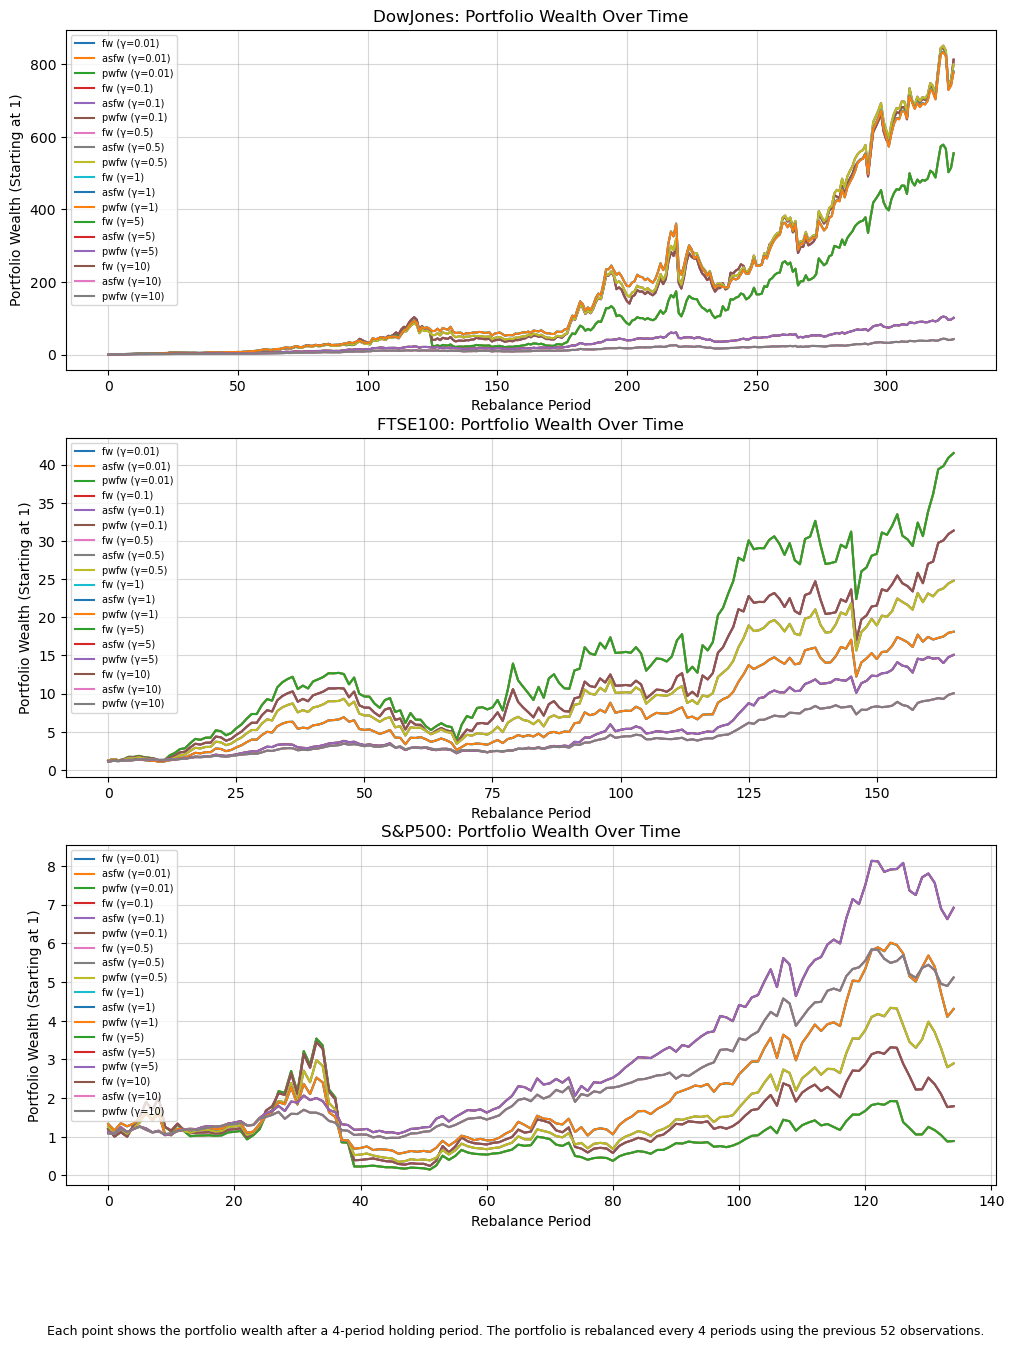

In [35]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))
for ax, (dataset_name, dataset_results) in zip(axes, all_results.items()):
    for gamma in gammas:
        df = dataset_results[gamma]
        for method in methods:
            method_df = df[
                df["method"] == method
            ].copy()
            method_df = method_df[
                method_df["forecast_horizon"] == 4
            ]
            method_df = method_df.sort_values(
                "rebalance_period"
            )
            ax.plot(
                method_df["rebalance_period"],
                method_df["budget"],
                label=f"{method.lower()} (γ={gamma})"
            )
    ax.set_title(f"{dataset_name}: Portfolio Wealth Over Time")
    ax.set_xlabel("Rebalance Period")
    ax.set_ylabel("Portfolio Wealth (Starting at 1)")
    ax.grid(True, alpha=0.5)
    ax.legend(fontsize=7, loc="upper left")

fig.text(
    0.5,
    0.01,
    "Each point shows the portfolio wealth after a 4-period holding period. "
    "The portfolio is rebalanced every 4 periods using the previous 52 observations.",
    ha="center",
    fontsize=9
)

plt.show()

In [25]:

summary = []
for dataset, results in all_results.items():
    for gamma in gammas:
        df = results[gamma]
        for method in methods:
            method_df = df[
                (df["method"] == method) &
                (df["forecast_horizon"] == 4)
            ].sort_values("rebalance_period")
            if method_df.empty:
                continue
            final = method_df["budget"].iloc[-1]
            summary.append([
                dataset,
                gamma,
                method,
                final
            ])
summary_df = pd.DataFrame(
    summary,
    columns=["Dataset", "Gamma", "Method", "Final Budget"]
)
best_overall = (summary_df.loc[
        summary_df.groupby("Dataset")["Final Budget"].idxmax()
    ]
    .sort_values("Dataset")
    .reset_index(drop=True)
)

print("\nBest Overall Result per Dataset:")
print(best_overall)


Best Overall Result per Dataset:
    Dataset  Gamma Method  Final Budget
0  DowJones   0.10   PWFW    812.104080
1   FTSE100   0.01     FW     41.500140
2    S&P500   5.00   PWFW      6.921917


In [33]:
selected_gammas = {
    'DowJones': 0.10,
    'FTSE100': 0.01,
    'S&P500': 5.00
}

methods = ("FW", "ASFW", "PWFW")

summary = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    model = PortfolioOptimisation_rolling(
        data=data,
        window_size=52,
        gamma=selected_gammas[name]
    )

    backtest = model.rolling_backtest(
        max_iter=10000,
        tol=1e-6,
        forecast_horizon=4,
        methods=methods
    )

    for method in methods:

        df = backtest[backtest['method'] == method]

        summary.append({
            'Dataset': name,
            'Gamma': selected_gammas[name],
            'Algorithm': method,
            'Iterations': df['iterations'].mean(),
            'Runtime (s)': df['runtime'].mean(),
            'Objective': df['objective'].mean(),
            'Final Gap': df['final_gap'].mean(),
            'Active Assets': df['active_assets'].mean()
        })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

 Dataset  Gamma Algorithm  Iterations  Runtime (s)  Objective     Final Gap  Active Assets
DowJones   0.10        FW    1.807339     0.000071  -0.013262  2.036629e-09       1.076453
DowJones   0.10      ASFW    1.785933     0.000077  -0.013262  8.990114e-10       1.076453
DowJones   0.10      PWFW    1.801223     0.000070  -0.013262  2.396063e-09       1.076453
 FTSE100   0.01        FW    2.024096     0.000083  -0.018063 -1.215380e-20       1.024096
 FTSE100   0.01      ASFW    2.024096     0.000078  -0.018063 -1.215380e-20       1.024096
 FTSE100   0.01      PWFW    2.024096     0.000080  -0.018063 -1.215380e-20       1.024096
  S&P500   5.00        FW 8910.451852     0.764946  -0.011766  2.608750e-06       9.155556
  S&P500   5.00      ASFW   47.200000     0.004920  -0.011767  7.521743e-07       7.955556
  S&P500   5.00      PWFW   35.059259     0.003131  -0.011767  7.279190e-07       7.962963
